## Task 1 - Stack Implementation and Trace

The stack uses a fixed-size Python list allocated once with `[None] * capacity`. Elements are stored by index; no built-in stack container, resizing, `append`, or list `pop` is used. The top index starts at `-1`. `PUSH` returns no value; `POP` and `PEEK` return the top element. Invalid operations raise an exception before changing the state.

The required trace uses `MAX_SIZE = 5`. Stack contents are shown from bottom to top, with zero-based indices. The `contents` helper creates a snapshot for display and verification; it is not a basic stack operation and is not used inside the timed regions.

In [1]:
class ArrayStack:
    def __init__(self, capacity):
        if not isinstance(capacity, int) or capacity < 0:
            raise ValueError('Capacity must be a nonnegative integer.')
        self.capacity = capacity
        self.data = [None] * capacity
        self.top = -1

    def is_empty(self):
        return self.top == -1

    def is_full(self):
        return self.top == self.capacity - 1

    def push(self, value):
        if self.is_full():
            raise OverflowError('Stack overflow')
        self.top += 1
        self.data[self.top] = value

    def pop(self):
        if self.is_empty():
            raise IndexError('Stack underflow')
        value = self.data[self.top]
        self.data[self.top] = None
        self.top -= 1
        return value

    def peek(self):
        if self.is_empty():
            raise IndexError('Invalid PEEK: stack is empty')
        return self.data[self.top]

    def contents(self):
        return self.data[:self.top + 1]


MAX_SIZE = 5
stack = ArrayStack(MAX_SIZE)
stack_operations = [
    ('PUSH', 10), ('PUSH', 20), ('PUSH', 30), ('PEEK', None),
    ('POP', None), ('PUSH', 40), ('PUSH', 50), ('PUSH', 60),
    ('PUSH', 70), ('POP', None), ('POP', None), ('POP', None),
    ('POP', None), ('POP', None), ('POP', None),
]
stack_trace = []
print(f"{'Operation':<12} {'Stack contents (bottom -> top)':<31} {'Top index':>9}  Result")
print('-' * 95)
for operation, argument in stack_operations:
    label = f'PUSH({argument})' if operation == 'PUSH' else f'{operation}()'
    try:
        if operation == 'PUSH':
            stack.push(argument)
            result = 'Inserted'
        elif operation == 'POP':
            result = f'Returned {stack.pop()}'
        else:
            result = f'Returned {stack.peek()}'
    except (OverflowError, IndexError) as error:
        result = str(error)
    stack_trace.append((label, stack.contents(), stack.top, result))
    print(f'{label:<12} {str(stack.contents()):<31} {stack.top:>9}  {result}')

assert stack.is_empty()
assert stack_trace[8] == ('PUSH(70)', [10, 20, 40, 50, 60], 4, 'Stack overflow')
assert stack_trace[-1] == ('POP()', [], -1, 'Stack underflow')

Operation    Stack contents (bottom -> top)  Top index  Result
-----------------------------------------------------------------------------------------------
PUSH(10)     [10]                                    0  Inserted
PUSH(20)     [10, 20]                                1  Inserted
PUSH(30)     [10, 20, 30]                            2  Inserted
PEEK()       [10, 20, 30]                            2  Returned 30
POP()        [10, 20]                                1  Returned 30
PUSH(40)     [10, 20, 40]                            2  Inserted
PUSH(50)     [10, 20, 40, 50]                        3  Inserted
PUSH(60)     [10, 20, 40, 50, 60]                    4  Inserted
PUSH(70)     [10, 20, 40, 50, 60]                    4  Stack overflow
POP()        [10, 20, 40, 50]                        3  Returned 60
POP()        [10, 20, 40]                            2  Returned 50
POP()        [10, 20]                                1  Returned 40
POP()        [10]                       

### Answers - Part C

1. **Why LIFO?** The most recently inserted element is at the top and is removed first. For example, pushing `10`, `20`, and `30` makes the next `POP` return `30`.
2. **What is the role of the top index?** It identifies the last occupied array position. `top = -1` means empty; the number of stored elements is `top + 1`.
3. **When does overflow occur?** A push is attempted when `top = capacity - 1`. In the trace, `PUSH(70)` fails because the five positions already contain `[10, 20, 40, 50, 60]`.
4. **When does underflow occur?** A pop is attempted when `top = -1`. The last `POP()` fails. `PEEK()` is also invalid on an empty stack.
5. **What are the operation costs?** `PUSH`, `POP`, `PEEK`, `ISEMPTY`, and `ISFULL` each take `Θ(1)` time and `Θ(1)` additional working space. The preallocated array uses `Θ(capacity)` space.

## Task 2 - Circular Queue Implementation and Trace

The circular queue uses one fixed-size array, `front_index`, `rear_index`, and `count`. Initially all three variables are zero. `front_index` identifies the next element to remove; `rear_index` identifies the **next insertion position**, as required by the assignment. Each advancing index wraps using `(index + 1) % capacity`.

The queue is empty when `count = 0` and full when `count = capacity`. This representation uses every array position. Equal front and rear indices can mean either empty or full; `count` distinguishes the two states. Queue contents below are shown in logical FIFO order, rather than physical array order. The snapshot helper takes `Θ(count)` time and is excluded from timing.

In [2]:
class CircularQueue:
    def __init__(self, capacity):
        if not isinstance(capacity, int) or capacity < 0:
            raise ValueError('Capacity must be a nonnegative integer.')
        self.capacity = capacity
        self.data = [None] * capacity
        self.front_index = 0
        self.rear_index = 0
        self.count = 0

    def is_empty(self):
        return self.count == 0

    def is_full(self):
        return self.count == self.capacity

    def enqueue(self, value):
        if self.is_full():
            raise OverflowError('Queue overflow')
        self.data[self.rear_index] = value
        self.rear_index = (self.rear_index + 1) % self.capacity
        self.count += 1

    def dequeue(self):
        if self.is_empty():
            raise IndexError('Queue underflow')
        value = self.data[self.front_index]
        self.data[self.front_index] = None
        self.front_index = (self.front_index + 1) % self.capacity
        self.count -= 1
        return value

    def front(self):
        if self.is_empty():
            raise IndexError('Invalid FRONT: queue is empty')
        return self.data[self.front_index]

    def contents(self):
        return [
            self.data[(self.front_index + offset) % self.capacity]
            for offset in range(self.count)
        ]


queue = CircularQueue(MAX_SIZE)
queue_operations = [
    ('ENQUEUE', 10), ('ENQUEUE', 20), ('ENQUEUE', 30), ('ENQUEUE', 40),
    ('DEQUEUE', None), ('DEQUEUE', None), ('ENQUEUE', 50), ('ENQUEUE', 60),
    ('ENQUEUE', 70), ('FRONT', None), ('DEQUEUE', None), ('ENQUEUE', 80),
    ('DEQUEUE', None), ('DEQUEUE', None), ('DEQUEUE', None),
    ('DEQUEUE', None), ('DEQUEUE', None),
]
queue_trace = []
print(f"{'Operation':<14} {'Queue contents (front -> rear)':<32} {'Front':>5} {'Rear':>5} {'Count':>6}  Result")
print('-' * 100)
for operation, argument in queue_operations:
    label = f'ENQUEUE({argument})' if operation == 'ENQUEUE' else f'{operation}()'
    try:
        if operation == 'ENQUEUE':
            queue.enqueue(argument)
            result = 'Inserted'
        elif operation == 'DEQUEUE':
            result = f'Returned {queue.dequeue()}'
        else:
            result = f'Returned {queue.front()}'
    except (OverflowError, IndexError) as error:
        result = str(error)
    queue_trace.append((
        label, queue.contents(), queue.front_index, queue.rear_index,
        queue.count, result,
    ))
    print(f'{label:<14} {str(queue.contents()):<32} {queue.front_index:>5} {queue.rear_index:>5} {queue.count:>6}  {result}')

assert queue_trace[8] == ('ENQUEUE(70)', [30, 40, 50, 60, 70], 2, 2, 5, 'Inserted')
assert queue_trace[9][-1] == 'Returned 30'
assert queue.is_empty() and queue.front_index == queue.rear_index == 3

Operation      Queue contents (front -> rear)   Front  Rear  Count  Result
----------------------------------------------------------------------------------------------------
ENQUEUE(10)    [10]                                 0     1      1  Inserted
ENQUEUE(20)    [10, 20]                             0     2      2  Inserted
ENQUEUE(30)    [10, 20, 30]                         0     3      3  Inserted
ENQUEUE(40)    [10, 20, 30, 40]                     0     4      4  Inserted
DEQUEUE()      [20, 30, 40]                         1     4      3  Returned 10
DEQUEUE()      [30, 40]                             2     4      2  Returned 20
ENQUEUE(50)    [30, 40, 50]                         2     0      3  Inserted
ENQUEUE(60)    [30, 40, 50, 60]                     2     1      4  Inserted
ENQUEUE(70)    [30, 40, 50, 60, 70]                 2     2      5  Inserted
FRONT()        [30, 40, 50, 60, 70]                 2     2      5  Returned 30
DEQUEUE()      [40, 50, 60, 70]              

### Answers - Part C

1. **Why FIFO?** Elements leave in their arrival order. Enqueuing `10`, `20`, and `30` makes `10` the first value dequeued.
2. **What do front and rear represent?** Front points to the next removal position; rear points to the next insertion position. The current number of elements is recorded separately.
3. **Why use a circular array?** A simple linear queue can reach the array end while earlier positions are free. A circular queue reuses those positions without shifting existing elements.
4. **How does modular arithmetic help?** With capacity five, `(4 + 1) % 5 = 0`, so advancing beyond the last index returns to the beginning. In the trace, inserting `50` wraps rear to zero; `60` and `70` then reuse positions zero and one.
5. **What are the operation costs?** `ENQUEUE`, `DEQUEUE`, `FRONT`, `ISEMPTY`, and `ISFULL` each take `Θ(1)` time and `Θ(1)` additional working space.

The prescribed queue sequence fills and empties the queue without attempting an invalid operation. At the full state, front and rear are both two and count is five; at the final empty state, front and rear are both three and count is zero. The additional checks below demonstrate overflow, underflow, and invalid reads explicitly. Failed operations must leave all state unchanged.

In [3]:
def expect_failure(action, exception_type, state):
    before = state()
    try:
        action()
    except exception_type as error:
        assert state() == before
        print(error)
    else:
        raise AssertionError(f'Expected {exception_type.__name__}')


empty_stack = ArrayStack(MAX_SIZE)
expect_failure(
    empty_stack.peek, IndexError,
    lambda: (empty_stack.top, empty_stack.data.copy()),
)
full_queue = CircularQueue(MAX_SIZE)
for value in range(1, MAX_SIZE + 1):
    full_queue.enqueue(value)
queue_state = lambda: (
    full_queue.front_index, full_queue.rear_index,
    full_queue.count, full_queue.data.copy(),
)
expect_failure(lambda: full_queue.enqueue(6), OverflowError, queue_state)
assert [full_queue.dequeue() for _ in range(MAX_SIZE)] == [1, 2, 3, 4, 5]
expect_failure(full_queue.dequeue, IndexError, queue_state)
expect_failure(full_queue.front, IndexError, queue_state)
print('Boundary checks passed; failed operations preserved the state.')

Invalid PEEK: stack is empty
Queue overflow
Queue underflow
Invalid FRONT: queue is empty
Boundary checks passed; failed operations preserved the state.


## Task 3 - Practical Applications

### Part A - Balanced Brackets

The bracket checker reuses `ArrayStack` with capacity exactly equal to the expression length. Opening brackets are pushed; a closing bracket must match the most recent unmatched opening bracket. Non-bracket characters are ignored. A mismatch, a closing bracket without an opening bracket, or unmatched openings at the end makes the expression invalid. The empty expression is balanced and safely uses a zero-capacity stack without any push.

In [4]:
def balanced_brackets(expression):
    stack = ArrayStack(len(expression))
    matching = {')': '(', ']': '[', '}': '{'}
    for character in expression:
        if character in '([{':
            stack.push(character)
        elif character in matching:
            if stack.is_empty() or stack.peek() != matching[character]:
                return False
            stack.pop()
    return stack.is_empty()


bracket_tests = [
    ('(a+b)', True),
    ('{[()]}', True),
    ('([)]', False),
    ('((a+b)', False),
    ('a+b*c', True),
    ('][', False),
]
print(f"{'Expression':<16} {'Expected':<16} Actual")
print('-' * 50)
for expression, expected in bracket_tests:
    actual = balanced_brackets(expression)
    assert actual == expected
    expected_label = 'Balanced' if expected else 'Not balanced'
    actual_label = 'Balanced' if actual else 'Not balanced'
    print(f'{expression:<16} {expected_label:<16} {actual_label}')

assert balanced_brackets('')
assert balanced_brackets('([]){}')
assert not balanced_brackets('(')
assert not balanced_brackets(')')

Expression       Expected         Actual
--------------------------------------------------
(a+b)            Balanced         Balanced
{[()]}           Balanced         Balanced
([)]             Not balanced     Not balanced
((a+b)           Not balanced     Not balanced
a+b*c            Balanced         Balanced
][               Not balanced     Not balanced


A stack is suitable because nested expressions must close the **most recently opened** bracket first. For `{[()]}`, `(` is matched before `[` and `{`. This is exactly LIFO order.

For an expression of length `n`, each character is scanned at most once and each bracket causes at most one push and one pop. The scan takes `O(n)` time, with `Θ(n)` worst-case time. Allocating the required length-`n` stack already costs `Θ(n)`, so this complete implementation takes `Θ(n)` time even when a mismatch is detected early. The fixed array requires `Θ(n)` auxiliary space; the number of live stack entries is bounded by the nesting depth.

### Part B - Customer Service Queue

The simulation reuses `CircularQueue` with capacity five. `ARRIVE` enqueues an integer customer ID, and `SERVE` dequeues the earliest waiting customer. Each row reports the event, its result, the remaining FIFO queue, and its length. A rejected arrival or a service request on an empty queue reports an error while preserving the queue.

In [5]:
service_queue = CircularQueue(MAX_SIZE)
customer_events = [
    ('ARRIVE', 101), ('ARRIVE', 102), ('ARRIVE', 103), ('SERVE', None),
    ('ARRIVE', 104), ('ARRIVE', 105), ('ARRIVE', 106), ('SERVE', None),
    ('SERVE', None), ('ARRIVE', 107), ('SERVE', None), ('SERVE', None),
    ('SERVE', None), ('SERVE', None),
]
served_customers = []
print(f"{'Event':<14} {'Result':<38} {'Waiting customers':<28} {'Length':>6}")
print('-' * 92)
for event, customer_id in customer_events:
    label = f'ARRIVE({customer_id})' if event == 'ARRIVE' else 'SERVE()'
    try:
        if event == 'ARRIVE':
            service_queue.enqueue(customer_id)
            result = f'Arrived {customer_id}'
            if service_queue.is_full():
                result += '; queue is full'
        else:
            served = service_queue.dequeue()
            served_customers.append(served)
            result = f'Served {served}'
    except OverflowError:
        result = f'Queue is full; {customer_id} cannot enter'
    except IndexError:
        result = 'Queue is empty; nobody to serve'
    print(f'{label:<14} {result:<38} {str(service_queue.contents()):<28} {service_queue.count:>6}')

print('Service order:', served_customers)
assert served_customers == [101, 102, 103, 104, 105, 106, 107]
assert service_queue.is_empty()

Event          Result                                 Waiting customers            Length
--------------------------------------------------------------------------------------------
ARRIVE(101)    Arrived 101                            [101]                             1
ARRIVE(102)    Arrived 102                            [101, 102]                        2
ARRIVE(103)    Arrived 103                            [101, 102, 103]                   3
SERVE()        Served 101                             [102, 103]                        2
ARRIVE(104)    Arrived 104                            [102, 103, 104]                   3
ARRIVE(105)    Arrived 105                            [102, 103, 104, 105]              4
ARRIVE(106)    Arrived 106; queue is full             [102, 103, 104, 105, 106]         5
SERVE()        Served 102                             [103, 104, 105, 106]              4
SERVE()        Served 103                             [104, 105, 106]                   3
ARRIVE(

### Answers

1. **Service order:** `101, 102, 103, 104, 105, 106, 107`. The queue becomes full after customer `106` arrives. Every specified arrival succeeds, and every specified service request finds a waiting customer.
2. **Why use a queue?** FIFO serves the customer who has waited longest. A stack would serve the latest arrival first and could indefinitely delay earlier customers.
3. **How can priorities be supported?** Use a priority queue ordered by priority and then arrival sequence, or keep one FIFO queue per priority level and choose the highest-priority nonempty queue. Equal-priority customers retain arrival order. An aging policy can increase priority with waiting time to reduce starvation.

## Task 4 - Experimental and Theoretical Analysis

### Parts A and B - Experimental Measurements

Use `n = 1000, 5000, 10000, 50000, 100000` and five independent timing runs for each size. Each run creates a fresh empty stack and queue, both with capacity `n`. The same integers `0` through `n - 1` are used for both structures.

All measurements use Python and `time.perf_counter()` in the same process on the same computer. Input preparation and fixed-array allocation occur **before** timing. Console output, snapshots, and correctness checks occur **outside** the timed regions. Each measured interval contains only its operation loop, including Python loop and method-call overhead. Push/enqueue and pop/dequeue are timed separately. The tables contain mean **total batch times**, rather than per-operation times. Exact measurements vary between runs and environments.

Stack operations: mean total batch time over five runs
       n      Push time (s)       Pop time (s)
----------------------------------------------
    1000           0.000346           0.000363
    5000           0.001768           0.001849
   10000           0.003578           0.003550
   50000           0.017802           0.018121
  100000           0.035527           0.036500

Queue operations: mean total batch time over five runs
       n   Enqueue time (s)   Dequeue time (s)
----------------------------------------------
    1000           0.000429           0.000475
    5000           0.002173           0.002404
   10000           0.004225           0.004881
   50000           0.021281           0.023740
  100000           0.043273           0.047886


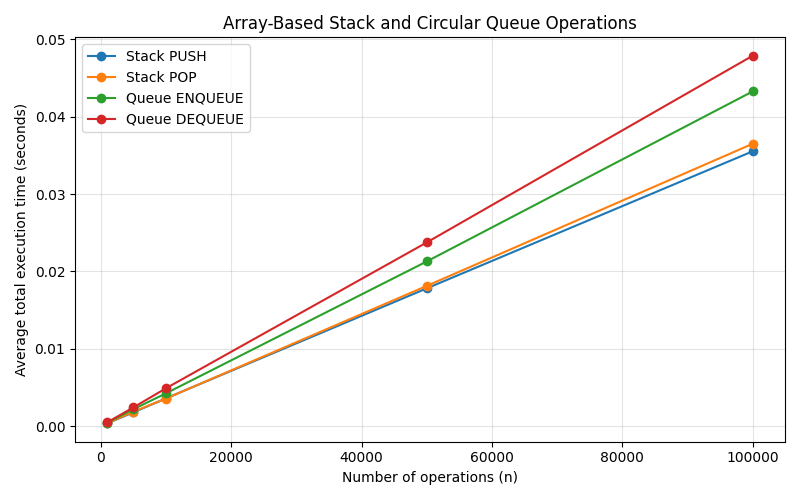

In [6]:
import time
import matplotlib.pyplot as plt


sizes = [1000, 5000, 10000, 50000, 100000]
repeats = 5
operation_names = ['Stack PUSH', 'Stack POP', 'Queue ENQUEUE', 'Queue DEQUEUE']
timing_runs = {name: [] for name in operation_names}
average_times = {name: [] for name in operation_names}

for n in sizes:
    values = list(range(n))
    samples = {name: [] for name in operation_names}
    for trial in range(repeats):
        stack = ArrayStack(n)
        queue = CircularQueue(n)

        start = time.perf_counter()
        for value in values:
            stack.push(value)
        push_elapsed = time.perf_counter() - start

        assert stack.is_full() and stack.contents() == values

        start = time.perf_counter()
        for _ in range(n):
            stack.pop()
        pop_elapsed = time.perf_counter() - start

        assert stack.is_empty() and stack.data == [None] * n

        start = time.perf_counter()
        for value in values:
            queue.enqueue(value)
        enqueue_elapsed = time.perf_counter() - start

        assert queue.is_full() and queue.contents() == values
        assert queue.front_index == queue.rear_index == 0

        start = time.perf_counter()
        for _ in range(n):
            queue.dequeue()
        dequeue_elapsed = time.perf_counter() - start

        assert queue.is_empty() and queue.data == [None] * n
        assert queue.front_index == queue.rear_index == 0
        elapsed_times = [push_elapsed, pop_elapsed, enqueue_elapsed, dequeue_elapsed]
        for name, elapsed in zip(operation_names, elapsed_times):
            samples[name].append(elapsed)

    for name in operation_names:
        timing_runs[name].append(samples[name])
        average_times[name].append(sum(samples[name]) / repeats)

print('Stack operations: mean total batch time over five runs')
print(f"{'n':>8} {'Push time (s)':>18} {'Pop time (s)':>18}")
print('-' * 46)
for n, push_time, pop_time in zip(sizes, average_times['Stack PUSH'], average_times['Stack POP']):
    print(f'{n:>8} {push_time:>18.6f} {pop_time:>18.6f}')

print('\nQueue operations: mean total batch time over five runs')
print(f"{'n':>8} {'Enqueue time (s)':>18} {'Dequeue time (s)':>18}")
print('-' * 46)
for n, enqueue_time, dequeue_time in zip(sizes, average_times['Queue ENQUEUE'], average_times['Queue DEQUEUE']):
    print(f'{n:>8} {enqueue_time:>18.6f} {dequeue_time:>18.6f}')

plt.figure(figsize=(8, 5))
for name in operation_names:
    plt.plot(sizes, average_times[name], marker='o', label=name)
plt.xlabel('Number of operations (n)')
plt.ylabel('Average total execution time (seconds)')
plt.title('Array-Based Stack and Circular Queue Operations')
plt.legend()
plt.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

### Part C - Complexity Analysis

| Operation | Time complexity | Auxiliary space per operation |
|---|---:|---:|
| Stack PUSH | `Θ(1)` | `Θ(1)` |
| Stack POP | `Θ(1)` | `Θ(1)` |
| Stack PEEK | `Θ(1)` | `Θ(1)` |
| Queue ENQUEUE | `Θ(1)` | `Θ(1)` |
| Queue DEQUEUE | `Θ(1)` | `Θ(1)` |
| Queue FRONT | `Θ(1)` | `Θ(1)` |

These costs exclude the preallocated structure, assume constant-time array access and machine-sized index arithmetic, and describe the basic operations without snapshots or printing. Overflow and underflow checks also take constant time. No operation shifts elements or resizes the array.

1. **Single push:** `Θ(1)` time because it checks fullness, advances one index, and writes one position.
2. **Single dequeue:** `Θ(1)` time because it checks emptiness, reads and clears one position, and updates an index and count.
3. **Why do `n` pushes take longer as `n` grows?** Constant work is repeated `n` times, so the total is `Θ(n)`. Constant time per operation does not mean constant time for a growing batch.
4. **Stack memory:** A fixed capacity `C` requires `Θ(C)` array storage plus `Θ(1)` metadata, even if few positions are occupied. To store `n` elements with capacity `C = n`, total structural storage is `Θ(n)`.
5. **Queue memory:** The same `Θ(C)` array storage is required, plus constant-sized front, rear, and count fields. Capacity `C = n` gives `Θ(n)` structural storage. In Python the list holds references; payload-object storage is additional and depends on the values.
6. **Relationship to measurements:** Each measured batch performs exactly `n` basic operations, so theoretical total time is `Θ(n)`. Approximate linear growth is expected, while timer noise, interpreter overhead, CPU scheduling, and cache effects prevent exact proportionality. The following table divides the measured batch mean by `n` to make this comparison visible. Queue operations also perform modular arithmetic and update an additional counter, so equal asymptotic complexity does not imply equal measured times.

In [7]:
print('Mean time per operation, derived from the measured batch times')
print(f"{'n':>8} {'PUSH (ns/op)':>16} {'POP (ns/op)':>16} {'ENQUEUE (ns/op)':>18} {'DEQUEUE (ns/op)':>18}")
print('-' * 80)
for index, n in enumerate(sizes):
    per_operation = [average_times[name][index] * 1e9 / n for name in operation_names]
    print(f'{n:>8} {per_operation[0]:>16.1f} {per_operation[1]:>16.1f} {per_operation[2]:>18.1f} {per_operation[3]:>18.1f}')

Mean time per operation, derived from the measured batch times
       n     PUSH (ns/op)      POP (ns/op)    ENQUEUE (ns/op)    DEQUEUE (ns/op)
--------------------------------------------------------------------------------
    1000            346.1            362.5              428.8              474.7
    5000            353.5            369.9              434.5              480.8
   10000            357.8            355.0              422.5              488.1
   50000            356.0            362.4              425.6              474.8
  100000            355.3            365.0              432.7              478.9


## Additional Theoretical Questions

1. **LIFO versus FIFO:** A stack removes the latest inserted element first; a queue removes the earliest inserted element first. After inserting `A`, `B`, `C`, a stack removes `C`, `B`, `A`, while a queue removes `A`, `B`, `C`.
2. **Two stack applications:** Undo history in an editor and nested function-call execution. Both process the most recent pending action first.
3. **Two queue applications:** A printer's FIFO job queue and customers waiting for service. Both preserve arrival order when priorities are absent.
4. **Recursion:** Each call pushes an activation record containing local state and a return location onto the call stack. The latest unfinished call completes first; popping its record resumes its caller. Maximum simultaneous recursion depth determines stack usage, and excessive depth can exhaust available stack space.
5. **BFS:** Enqueue the start vertex and mark it visited. Repeatedly dequeue a vertex and enqueue its unvisited neighbors, marking them when enqueued to avoid duplicate entries. FIFO processing explores vertices by increasing distance from the start in an unweighted graph. With adjacency lists, BFS takes `Θ(V + E)` time for the reachable graph and `O(V)` auxiliary space. A queue of capacity equal to the total number of vertices is sufficient when each vertex is enqueued once.
6. **Array-based versus linked-list-based structures:**

| Property | Fixed-size array | Linked list |
|---|---|---|
| Stack push/pop | `Θ(1)` | `Θ(1)` at the head |
| Queue enqueue/dequeue | `Θ(1)` using circular indices | `Θ(1)` with both head and tail pointers |
| Capacity | Chosen when allocated; can overflow | Can grow until allocation fails |
| Structural memory | `Θ(C)` allocated slots for capacity `C` | `Θ(n)` nodes for `n` stored elements, including link overhead |
| Locality | Contiguous references usually give better cache locality | Nodes can be scattered in memory |
| Main trade-off | Unused reserved slots and a fixed capacity | Per-node allocation and pointer overhead |

The linked-list operation bounds use the standard constant-time allocation model. A queue that keeps only a head pointer and searches for its tail would require linear-time enqueue. A dynamically resized array is a different design: growth may make an individual insertion `Θ(n)`, even when insertion is amortized `Θ(1)`.

## Conclusion

Stacks and queues both support constant-time insertion, removal, and inspection when implemented with fixed arrays and suitable indices. Their ordering rules determine their uses: LIFO handles nested brackets and function calls, while FIFO preserves customer arrival order and supports BFS.

The stack trace demonstrates overflow and underflow. The circular queue trace demonstrates wraparound and reuse of positions without shifting; separate boundary checks verify invalid queue operations and empty reads. All required bracket expressions and customer events are processed using the implemented structures. The experiments measure complete batches at five sizes with five runs each, allowing the expected linear total work to be compared with constant work per operation. Both structures require space proportional to their allocated capacity.